In [60]:
import pandas as pd

# Load the dataset without a header row
data = pd.read_csv("/GCL.csv", header=None)

# Display the first five rows
print(data.head())

# Check the number of rows and columns
print(data.shape)


     0      1      2      3      4      5      6      7      8         9   \
0  44.0   69.0   91.0  107.0  123.0  142.0  163.0  191.0  242.1  0.000019   
1  17.0   33.0   47.0   64.0   86.0  104.1  125.0  147.0  182.0  0.000043   
2  87.0  108.0  123.0  135.0  147.0  159.0  171.0  186.0  212.0  0.000042   
3  62.0   85.0  104.0  119.0  133.0  148.0  163.0  184.0  218.0  0.000024   
4  60.0   80.0   95.0  109.0  122.0  136.0  149.0  167.0  194.0  0.000030   

   ...       18      19      20      21      22      23      24      25  \
0  ...   0.0000  17.617  25.426  27.397  29.325  31.252  35.459  42.978   
1  ...   7.6606  25.409  29.339  33.010  35.022  37.048  37.426  41.021   
2  ...  11.7710  23.748  27.160  30.865  31.269  33.203  35.156  37.109   
3  ...  11.8020  21.914  31.055  32.844  34.783  36.722  38.680  40.625   
4  ...   2.8990  27.347  31.129  32.958  35.033  37.293  41.040  50.918   

       26  27  
0  53.140   0  
1  45.623   0  
2  39.073   0  
3  42.578   0  
4  64.

In [61]:
# Separate the features and target labels

x = data.iloc[:, 0:27]
y = data.iloc[:, 27]

# Check the dimensions
print("Features shape:", x.shape)
print("Labels shape:", y.shape)

#Display the different classes
print("Unique classes:", y.unique())

Features shape: (541, 27)
Labels shape: (541,)
Unique classes: [0 1 2]


In [62]:
# Import the tarin-test split function
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
   x,y,
   test_size=0.20,
   random_state=42,
   stratify=y
)


# Display the number of observations
print("Training features:", x_train.shape)
print("Testing features:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (432, 27)
Testing features: (432,)
Testing labels: (109,)


In [63]:
# Import the StandardScaler
from sklearn.preprocessing import StandardScaler

# Create a scaler
scaler = StandardScaler()

# Scale the training data
x_train_scaled = scaler.fit_transform(x_train)

# Scale the testing data
x_test_scaled = scaler.transform(x_test)

# Display the first scaled training observation
print("First scaled observation:")
print(x_train_scaled[0])

First scaled observation:
[-1.01787482 -1.15638866 -1.27236462 -1.37496435 -1.47519956 -1.57651352
 -1.66904569 -1.80900834 -1.96876015 -0.48707807 -0.6279198  -0.68887267
 -0.72244492 -0.68065318 -0.74999533 -0.84993005 -1.05585436 -0.87288457
  0.81132738 -0.09386695 -0.30224221 -0.36725478 -0.22491107 -0.1149075
 -0.04010493 -0.0307089  -0.13341736]


In [64]:
# Import the KNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Create a KNN model with k = 3
knn3 = KNeighborsClassifier(n_neighbors=3)

# Train the KNN classifier
knn3.fit(x_train_scaled, y_train)

# Predict the classes for the testing data
y_pred3 = knn3.predict(x_test_scaled)

# Display the first 10 predictions
print("First 10 predictions:")
print(y_pred3[:10])

# Display the first 10 actual labels
print("First 10 actual labels:")
print(y_test[:10].values)


First 10 predictions:
[0 1 2 2 2 1 2 2 2 2]
First 10 actual labels:
[0 1 2 2 2 1 2 2 2 2]


In [65]:

from sklearn.metrics import accuracy_score, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred3)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred3, labels=[0, 1, 2])

# Calculate sensitivity and specificity
for i in range(3):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    print(f"Class {i}:")
    print(f"  Sensitivity: {sensitivity:.4f}")
    print(f"  Specificity: {specificity:.4f}")
    print()

# Print overall accuracy
print(f"Overall Accuracy: {accuracy:.4f}")
print(f"Overall Accuracy (%): {accuracy * 100:.2f}%")



Class 0:
  Sensitivity: 0.9615
  Specificity: 0.9880

Class 1:
  Sensitivity: 1.0000
  Specificity: 0.9881

Class 2:
  Sensitivity: 0.9655
  Specificity: 0.9804

Overall Accuracy: 0.9725
Overall Accuracy (%): 97.25%


In [66]:

# Create a KNN classifier with k = 5
knn5 = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn5.fit(x_train_scaled, y_train)

# Make predictions
y_pred5 = knn5.predict(x_test_scaled)

# Calculate the confusion matrix
cm5 = confusion_matrix(y_test, y_pred5, labels=[0, 1, 2])

# Display the confusion matrix
print("Confusion Matrix for KNN (k=5):")
print(cm5)

# Calculate accuracy for comparison
accuracy5 = accuracy_score(y_test, y_pred5)

print(f"Accuracy for k=5: {accuracy5 * 100:.2f}%")


Confusion Matrix for KNN (k=5):
[[25  0  1]
 [ 0 24  1]
 [ 1  1 56]]
Accuracy for k=5: 96.33%


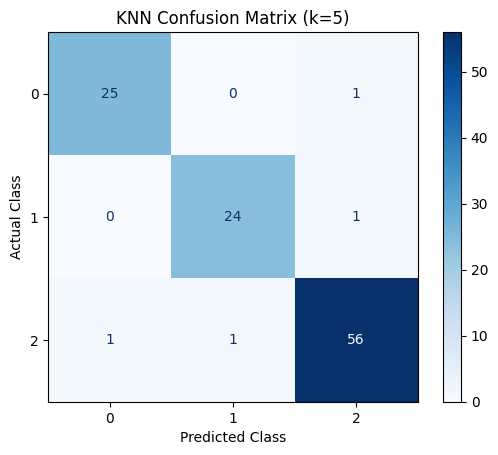

In [67]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create a confusion matrix visualization
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm5,
    display_labels=[0, 1, 2]
)

# Display the visualization
disp.plot(cmap="Blues")

plt.title("KNN Confusion Matrix (k=5)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()
